In [9]:
import pandas as pd
from pathlib import Path

data_dir = Path('../data')

df = pd.read_csv(data_dir/'SMSSpamCollection',
            sep = '\t',
            header = None,
            names = ['label', 'message']
            )

df.head()


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df.isnull().sum()

label      0
message    0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(403)

In [11]:
df = df.drop_duplicates()

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5169 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5169 non-null   object
 1   message  5169 non-null   object
dtypes: object(2)
memory usage: 121.1+ KB


<Axes: xlabel='count', ylabel='label'>

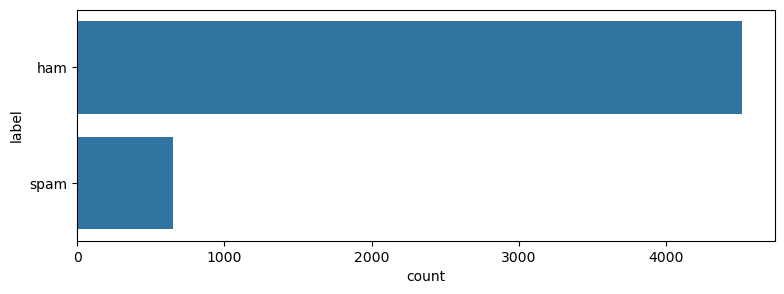

In [13]:
import seaborn as sns 
import matplotlib.pyplot as plt
fig = plt.figure(figsize = (9, 3))
sns.countplot(df['label'])

In [14]:
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True) * 100)

label
ham     4516
spam     653
Name: count, dtype: int64
label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


In [15]:
import nltk
import re

df['message'] = df['message'].str.lower()

In [16]:
df['message'] = df['message'].map(lambda x : re.sub(r"http\S+|www\.\S+", "", x))

In [17]:
df['message'] = df['message'].map(lambda x : re.sub(r'[^0-9a-z\s]', '', x))

In [18]:
df['message'].head()

0    go until jurong point crazy available only in ...
1                              ok lar joking wif u oni
2    free entry in 2 a wkly comp to win fa cup fina...
3          u dun say so early hor u c already then say
4    nah i dont think he goes to usf he lives aroun...
Name: message, dtype: object

In [19]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def stop_word(text):
    text = text.split()
    filtered_text = [word for word in text if word not in ENGLISH_STOP_WORDS]
    final_text = ' '.join(filtered_text)

    return final_text
            
df['message'] = df['message'].map(lambda x : stop_word(x))
df['message'].head()

0    jurong point crazy available bugis n great wor...
1                              ok lar joking wif u oni
2    free entry 2 wkly comp win fa cup final tkts 2...
3                          u dun say early hor u c say
4                        nah dont think goes usf lives
Name: message, dtype: object

# steaming and lemmatization

In [20]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

nltk.download("wordnet")
nltk.download("omw-1.4")

def stem_(text):
    words = text.split()

    words = [ stemmer.stem(word) for word in words]
    words = [lemmatizer.lemmatize(word) for word in words]
    text = ' '.join(words)
    
    return text

df['message'] = df['message'].map(lambda x : stem_(x))
df['message'].head()
    
    


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\vishw\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\vishw\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


0    jurong point crazi avail bugi n great world la...
1                                ok lar joke wif u oni
2    free entri 2 wkli comp win fa cup final tkt 21...
3                          u dun say earli hor u c say
4                          nah dont think goe usf live
Name: message, dtype: object

In [21]:
from sklearn.model_selection import train_test_split

X = df['message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X_train_transformed = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)


In [23]:
vectorizer

TfidfVectorizer()

In [24]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB(alpha = 0.1)

model.fit(X_train_transformed, y_train)

MultinomialNB(alpha=0.1)

In [25]:
y_pred = model.predict(X_test)

In [28]:
from sklearn.metrics import classification_report, confusion_matrix

report = classification_report(y_test, y_pred)
matrix = confusion_matrix(y_pred= y_pred, y_true= y_test, labels = ['ham', 'spam'])

print(report)  
print(matrix)

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       894
        spam       0.97      0.90      0.93       140

    accuracy                           0.98      1034
   macro avg       0.98      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034

[[890   4]
 [ 14 126]]


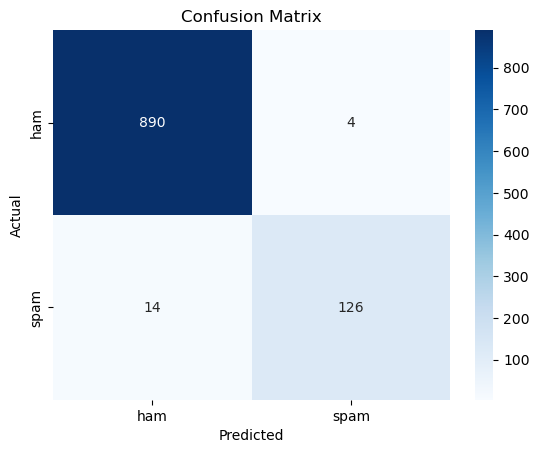

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    matrix,
    annot = True,
    fmt = 'd',
    cmap = 'Blues',
    xticklabels = ['ham', 'spam'],
    yticklabels = ['ham', 'spam']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()